In [2]:
from sklearn.linear_model import Lasso
from sklearn.metrics import mean_squared_error
import pandas as pd
from sklearn.model_selection import train_test_split

In [3]:
insurance_data = pd.read_csv('insurance.csv')
X = insurance_data.drop(columns=['charges'])
y = insurance_data['charges']

X = pd.get_dummies(X,columns=['region'],drop_first=True,dtype=int)

X['sex'] = X['sex'].map({'female':1,'male':0})
X['smoker'] = X['smoker'].map({'yes':1,'no':0}) 

X['age-smoker'] = X['age'] * X['smoker']
X['bmi-smoker'] = X['bmi'] * X['smoker']

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42)

MSE for alpha=0.001: 20922599.87103596
MSE for alpha=0.1: 20921803.69843138
MSE for alpha=1: 20914832.635089137
MSE for alpha=2: 20908106.779954515
MSE for alpha=3: 20901927.931570224
MSE for alpha=5: 20890881.000633497
MSE for alpha=100: 22423172.686023254


<Axes: >

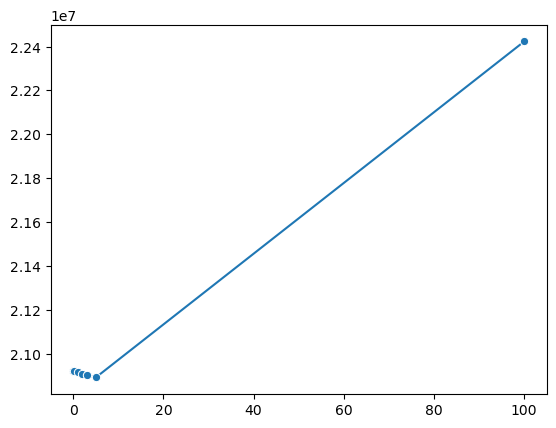

In [4]:
import seaborn as sns

alphas = [0.001,0.1,1,2,3,5,100]
mses = []

for a in alphas:
    lasso_model = Lasso(alpha=a)
    lasso_model.fit(X_train,y_train)

    y_pred = lasso_model.predict(X_test)
    mse = mean_squared_error(y_test,y_pred)
    print(f'MSE for alpha={a}:' ,mse)
    mses.append(mse)

sns.lineplot(x=alphas,y=mses,marker='o')

In [6]:
#LassoCV
from sklearn.linear_model import LassoCV
a = [0.001,0.1,1,2,3,4,55]

lasso_cv_model = LassoCV(
    alphas=a,
    cv=5,
    max_iter=1000,
    random_state = 42
)

lasso_cv_model.fit(X_train,y_train)

print('best alpha:',lasso_cv_model.alpha_)

y_pred = lasso_cv_model.predict(X_test)
mse = mean_squared_error(y_test,y_pred)
print('mse = ',mse)

best alpha: 0.001
mse =  20922599.87103596
